# Mobile Price Classification: Exploratory Data Analysis

**Dataset:** Kaggle "Mobile Price Classification" (`train.csv`, `test.csv`).

**Goal:** understand the data well enough to  model choice for predicting `price_range` (0 = low, 1 = medium, 2 = high, 3 = very high).

**How train and test are used here**

`test.csv` has no `price_range` column (it has an `id` column instead), so the two files cannot simply be merged and treated as one dataset.

- The files are stacked into one frame with a `source` column. This combined frame is used only for **feature-level** checks: data quality, distributions, and train vs test comparison.
- Everything involving the **target** (`price_range`) uses **train only**.
- This is exploration only. Nothing is fitted on the combined data, so there is no leakage. During modelling, scalers and encoders must still be fitted on the training split only.

## 1. Setup and loading

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# One consistent visual style for the whole notebook
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.frameon": False,
    "legend.fontsize": 9, "font.family": "DejaVu Sans",
})

# price_range is ordered, so it gets one hue from light to dark
PRICE_COLORS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
PRICE_LABELS = {0: "0 Low", 1: "1 Medium", 2: "2 High", 3: "3 Very high"}
# train / test are two unordered groups
SRC_COLORS = {"train": "#2a78d6", "test": "#eb6834"}
BLUE = "#2a78d6"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f0efec", "#2a78d6"])
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#86b6ef", "#0d366b"])

In [39]:
train = pd.read_excel("Train cleaned.xlsx")
test = pd.read_csv("test.csv")

TARGET = "price_range"
FEATURES = [c for c in train.columns if c != TARGET]

BINARY = ["blue", "dual_sim", "four_g", "three_g", "touch_screen", "wifi"]
DISCRETE = ["fc", "pc", "n_cores", "sc_h", "sc_w", "talk_time", "m_dep"]      # few distinct values
CONTINUOUS = ["battery_power", "clock_speed", "int_memory", "mobile_wt",
              "px_height", "px_width", "ram"]
NUMERIC = CONTINUOUS + DISCRETE
assert sorted(BINARY + NUMERIC) == sorted(FEATURES)

# Combined frame for feature-level checks only (the target is NaN for test rows)
combined = pd.concat(
    [train.assign(source="train"), test.drop(columns="id").assign(source="test")],
    ignore_index=True,
)

print("train   :", train.shape)
print("test    :", test.shape)
print("combined:", combined.shape)
print("columns only in train:", sorted(set(train.columns) - set(test.columns)))
print("columns only in test :", sorted(set(test.columns) - set(train.columns)))

train   : (1998, 21)
test    : (1000, 21)
combined: (2998, 22)
columns only in train: ['price_range']
columns only in test : ['id']


**Findings**

- `train.csv` has 2,000 phones and 21 columns: 20 features plus the target `price_range`.
- `test.csv` has 1,000 phones and 21 columns: the same 20 features plus an `id` column, and **no `price_range`**.
- The combined frame therefore has 3,000 rows, of which only the 2,000 train rows carry a label. Test rows cannot be used to measure model accuracy.

## 2. Structure and data dictionary

In [40]:
train.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.200,0,1,0,7,0.600,188,2,2,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.500,1,0,1,53,0.700,136,3,6,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.500,1,2,1,41,0.900,145,5,6,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.500,0,0,0,10,0.800,131,6,9,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.200,0,13,1,44,0.600,141,2,14,1208,1212,1411,8,2,15,1,1,0,1


In [41]:
test.head()

,id,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,1,1043,1,1.800,1,14,0,5,0.100,193,3,16,226,1412,3476,12,7,2,0,1,0
1,2,841,1,0.500,1,4,1,61,0.800,191,5,12,746,857,3895,6,0,7,1,0,0
2,3,1807,1,2.800,0,1,0,27,0.900,186,3,4,1270,1366,2396,17,10,10,0,1,1
3,4,1546,0,0.500,1,18,1,25,0.500,96,8,20,295,1752,3893,10,0,7,1,1,0
4,5,1434,0,1.400,0,11,1,49,0.500,108,6,18,749,810,1773,15,8,7,1,0,1


In [42]:
dictionary = {
    "battery_power": ("Battery capacity", "mAh"),
    "blue": ("Has Bluetooth", "0/1"),
    "clock_speed": ("Processor clock speed", "GHz"),
    "dual_sim": ("Has dual SIM support", "0/1"),
    "fc": ("Front camera resolution", "megapixels"),
    "four_g": ("Has 4G", "0/1"),
    "int_memory": ("Internal memory", "GB"),
    "m_dep": ("Mobile depth (thickness)", "cm"),
    "mobile_wt": ("Weight", "grams"),
    "n_cores": ("Number of processor cores", "count"),
    "pc": ("Primary camera resolution", "megapixels"),
    "px_height": ("Pixel resolution height", "pixels"),
    "px_width": ("Pixel resolution width", "pixels"),
    "ram": ("RAM", "MB"),
    "sc_h": ("Screen height", "cm"),
    "sc_w": ("Screen width", "cm"),
    "talk_time": ("Longest time one charge lasts on a call", "hours"),
    "three_g": ("Has 3G", "0/1"),
    "touch_screen": ("Has touch screen", "0/1"),
    "wifi": ("Has WiFi", "0/1"),
    "price_range": ("TARGET: 0 low, 1 medium, 2 high, 3 very high", "class"),
}
overview = pd.DataFrame(dictionary, index=["description", "unit"]).T
overview["dtype"] = train.dtypes.astype(str)
overview["n_unique (train)"] = train.nunique()
overview["min"] = train.min()
overview["max"] = train.max()
overview["type"] = ["binary" if c in BINARY else "target" if c == TARGET
                    else "discrete" if c in DISCRETE else "continuous" for c in overview.index]
overview

,description,unit,dtype,n_unique (train),min,max,type
battery_power,Battery capacity,mAh,int64,1093,501.000,"1,998.000",continuous
blue,Has Bluetooth,0/1,int64,2,0.000,1.000,binary
clock_speed,Processor clock speed,GHz,float64,26,0.500,3.000,continuous
dual_sim,Has dual SIM support,0/1,int64,2,0.000,1.000,binary
fc,Front camera resolution,megapixels,int64,20,0.000,19.000,discrete
four_g,Has 4G,0/1,int64,2,0.000,1.000,binary
int_memory,Internal memory,GB,int64,63,2.000,64.000,continuous
m_dep,Mobile depth (thickness),cm,float64,10,0.100,1.000,discrete
mobile_wt,Weight,grams,int64,121,80.000,200.000,continuous
n_cores,Number of processor cores,count,int64,8,1.000,8.000,discrete


In [43]:
train[NUMERIC].describe().T.assign(
    skew=train[NUMERIC].skew(), kurtosis=train[NUMERIC].kurt()
)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
battery_power,"1,998.000","1,238.391",439.370,501.000,851.250,"1,226.000","1,615.000","1,998.000",0.032,-1.223
clock_speed,"1,998.000",1.522,0.816,0.500,0.700,1.500,2.200,3.000,0.180,-1.323
int_memory,"1,998.000",32.058,18.141,2.000,16.000,32.000,48.000,64.000,0.058,-1.217
mobile_wt,"1,998.000",140.263,35.404,80.000,109.000,141.000,170.000,200.000,0.006,-1.210
px_height,"1,998.000",645.754,443.533,1.000,284.000,565.500,947.750,"1,960.000",0.667,-0.316
px_width,"1,998.000","1,251.276",432.064,500.000,874.250,"1,247.000","1,632.750","1,998.000",0.014,-1.186
ram,"1,998.000","2,123.512","1,084.701",256.000,"1,206.500","2,146.500","3,063.750","3,998.000",0.007,-1.192
fc,"1,998.000",4.309,4.343,0.000,1.000,3.000,7.000,19.000,1.020,0.276
pc,"1,998.000",9.916,6.067,0.000,5.000,10.000,15.000,20.000,0.018,-1.173
n_cores,"1,998.000",4.519,2.288,1.000,3.000,4.000,7.000,8.000,0.004,-1.230


**Findings**

- Every column is already numeric (19 integer, 2 float: `clock_speed` and `m_dep`), so no categorical encoding is needed.
- There are 6 binary features, 7 discrete features with 8 to 21 distinct values, and 7 continuous features.
- Scales differ by orders of magnitude (`m_dep` runs 0.1 to 1.0, `ram` runs 256 to 3,998), so distance-based and linear models need scaling.
- Most numeric features have skew close to 0 and kurtosis close to -1.2, which is the signature of a uniform distribution. Real phone specifications are not spread evenly like this, so the data looks simulated. The exceptions are `fc` (skew 1.02), `px_height` (0.67) and `sc_w` (0.63).

## 3. Data quality

Checked on both files, since the preprocessing has to handle both.

### 3.1 Missing values and duplicates

In [44]:
quality = pd.DataFrame({
    "missing (train)": train[FEATURES].isna().sum(),
    "missing (test)": test[FEATURES].isna().sum(),
})
print("Total missing values  train:", int(train.isna().sum().sum()), "| test:", int(test.isna().sum().sum()))
print("Duplicate rows        train:", int(train.duplicated().sum()),
      "| test (ignoring id):", int(test.drop(columns='id').duplicated().sum()))
print("Duplicate feature rows in train with different labels:",
      int(train.duplicated(subset=FEATURES, keep=False).sum()))
print("Rows appearing in both train and test:", len(pd.merge(train[FEATURES], test[FEATURES], on=FEATURES)))
print("test id is unique and runs 1..n:", test["id"].is_unique and test["id"].min() == 1 and test["id"].max() == len(test))

Total missing values  train: 0 | test: 0
Duplicate rows        train: 0 | test (ignoring id): 0
Duplicate feature rows in train with different labels: 0
Rows appearing in both train and test: 0
test id is unique and runs 1..n: True


### 3.2 Values that are not physically plausible

There are no NaNs, but missing or bad values can be hidden as zeros or tiny numbers. Each check below counts rows that break a rule a real phone should satisfy.

In [45]:
def checks(df):
    return pd.Series({
        "sc_w == 0 (screen width 0 cm)": (df.sc_w == 0).sum(),
        "sc_w between 1 and 2 cm (very narrow)": df.sc_w.between(1, 2).sum(),
        "px_height == 0": (df.px_height == 0).sum(),
        "px_height < 100 px (unrealistically low)": (df.px_height < 100).sum(),
        "pc == 0 (no primary camera)": (df.pc == 0).sum(),
        "fc == 0 (no front camera)": (df.fc == 0).sum(),
        "fc > pc (front camera better than primary)": (df.fc > df.pc).sum(),
        "four_g == 1 but three_g == 0": ((df.four_g == 1) & (df.three_g == 0)).sum(),
        "sc_w > sc_h": (df.sc_w > df.sc_h).sum(),
        "px_height > px_width": (df.px_height > df.px_width).sum(),
        "any negative value": (df[FEATURES] < 0).any(axis=1).sum(),
    })

plaus = pd.DataFrame({"train": checks(train), "test": checks(test)})
plaus["train %"] = (plaus["train"] / len(train) * 100).round(1)
plaus["test %"] = (plaus["test"] / len(test) * 100).round(1)
plaus

,train,test,train %,test %
sc_w == 0 (screen width 0 cm),0,112,0.000,11.200
sc_w between 1 and 2 cm (very narrow),366,206,18.300,20.600
px_height == 0,0,2,0.000,0.200
px_height < 100 px (unrealistically low),148,99,7.400,9.900
pc == 0 (no primary camera),101,40,5.100,4.000
fc == 0 (no front camera),474,210,23.700,21.000
fc > pc (front camera better than primary),0,0,0.000,0.000
four_g == 1 but three_g == 0,0,0,0.000,0.000
sc_w > sc_h,22,0,1.100,0.000
px_height > px_width,0,0,0.000,0.000


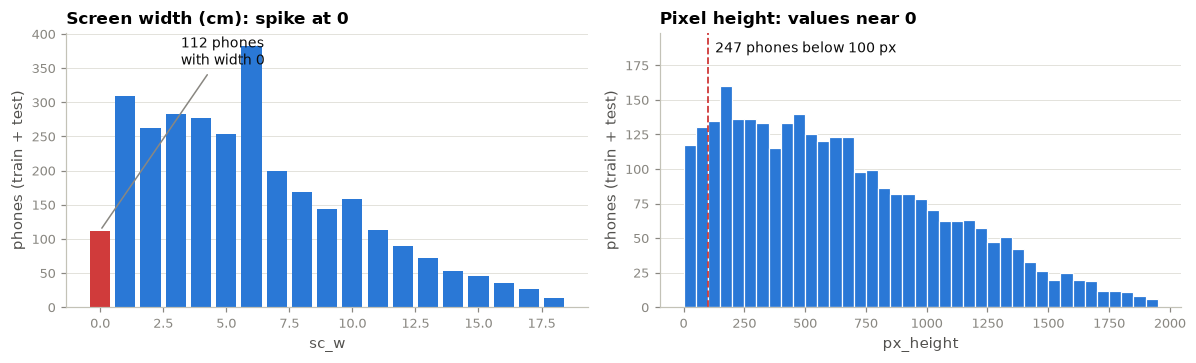

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, col, title in zip(axes, ["sc_w", "px_height"],
                          ["Screen width (cm): spike at 0", "Pixel height: values near 0"]):
    if col == "sc_w":
        counts = combined[col].value_counts().sort_index()
        colors = ["#d03b3b" if v == 0 else BLUE for v in counts.index]
        ax.bar(counts.index, counts.values, color=colors, width=0.8)
        ax.annotate(f"{counts.loc[0]} phones\nwith width 0", xy=(0, counts.loc[0]), xytext=(3.2, counts.max() * 0.93),
                    fontsize=9, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED))
    else:
        ax.hist(combined[col], bins=np.arange(0, 2000, 50), color=BLUE, edgecolor="white", linewidth=0.8)
        ax.axvline(100, color="#d03b3b", linewidth=1.2, linestyle="--")
        ax.set_ylim(0, ax.get_ylim()[1] * 1.18)
        ax.text(130, ax.get_ylim()[1] * 0.93, f"{(combined[col] < 100).sum()} phones below 100 px", fontsize=9, color=INK)
    ax.set_title(title, loc="left"); ax.set_xlabel(col); ax.set_ylabel("phones (train + test)")
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [47]:
# Do the suspicious groups differ in price mix? (train only; rows sum to 1)
for name, flag in {"sc_w == 0": train.sc_w == 0, "px_height < 100": train.px_height < 100}.items():
    tab = pd.crosstab(flag, train[TARGET])
    pval = stats.chi2_contingency(tab)[1]
    print(f"{name}  (chi-square p = {pval:.3f})")
    print(tab.div(tab.sum(axis=1), axis=0).round(3).rename(index={False: "  no", True: "  yes"}).to_string(), "\n")

sc_w == 0  (chi-square p = 1.000)
price_range     0     1     2     3
sc_w                               
no          0.250 0.250 0.250 0.250 

px_height < 100  (chi-square p = 0.037)
price_range     0     1     2     3
px_height                          
no          0.243 0.250 0.251 0.256
yes         0.338 0.243 0.243 0.176 



### 3.3 Outliers (1.5 x IQR rule) and skewness

In [48]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

out = pd.DataFrame({
    "outliers (train)": train[NUMERIC].apply(iqr_outliers),
    "outliers (test)": test[NUMERIC].apply(iqr_outliers),
    "skew (train)": train[NUMERIC].skew().round(2),
}).sort_values("skew (train)", ascending=False)
out

,outliers (train),outliers (test),skew (train)
fc,18,14,1.020
sc_w,0,5,0.710
px_height,2,2,0.670
clock_speed,0,0,0.180
m_dep,0,0,0.090
int_memory,0,0,0.060
battery_power,0,0,0.030
pc,0,0,0.020
px_width,0,0,0.010
mobile_wt,0,0,0.010


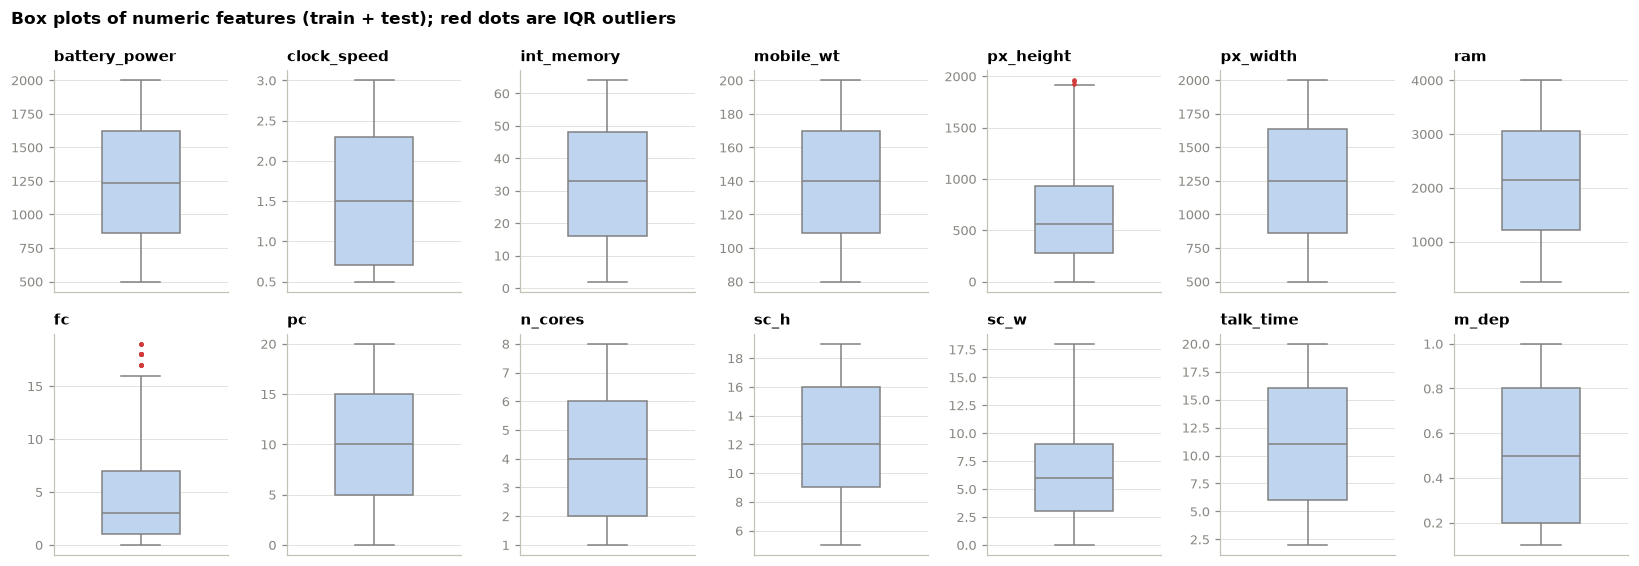

In [49]:
fig, axes = plt.subplots(2, 7, figsize=(15, 5.2))
for ax, col in zip(axes.ravel(), NUMERIC):
    sns.boxplot(y=combined[col], ax=ax, color="#b7d3f6", width=0.45, linewidth=1,
                flierprops=dict(marker="o", markersize=3, markerfacecolor="#d03b3b", markeredgecolor="none"))
    ax.set_title(col, fontsize=10, loc="left"); ax.set_ylabel(""); ax.set_xticks([])
fig.suptitle("Box plots of numeric features (train + test); red dots are IQR outliers", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

**Findings**

- **No missing values and no duplicate rows** in either file, and no row appears in both files.
- **`sc_w` = 0** (a screen 0 cm wide) occurs in 180 train rows (9.0%) and 112 test rows (11.2%). These are almost certainly hidden missing values. A further 366 train and 206 test rows have a width of only 1 to 2 cm, which is also hard to believe for screens 5 to 19 cm tall.
- **`px_height`** is 0 in 2 train and 2 test rows, and below 100 px in 150 train rows (7.5%) and 99 test rows (9.9%).
- **`pc` = 0** (101 train, 40 test) and **`fc` = 0** (474 train, 210 test) are plausible: they can mean the phone has no such camera. These should be kept.
- All logical rules hold in every row: `fc` never exceeds `pc`, no phone has 4G without 3G, `sc_w` never exceeds `sc_h`, and `px_height` never exceeds `px_width`.
- The price mix of the `sc_w` = 0 group is not significantly different from the rest (chi-square p = 0.679). The `px_height` < 100 group leans towards the low price range (33.3% low against 24.3% for other phones), but this is borderline (p = 0.051) and matches the general trend that fewer pixels means a lower price.
- The IQR rule flags very few points: 18 train and 14 test rows in `fc` (values of 17 to 19 MP), 2 and 2 in `px_height`, and 5 test rows in `sc_w`. These are the tail of skewed but valid ranges, not errors.

## 4. Train vs test comparison

If test phones were distributed differently from train phones, a model validated on train would be misleading. Three checks: summary statistics, a per-feature statistical test, and an "adversarial" classifier that tries to tell the two files apart.

In [50]:
cmp = pd.DataFrame({
    "train mean": train[FEATURES].mean(), "test mean": test[FEATURES].mean(),
    "train std": train[FEATURES].std(), "test std": test[FEATURES].std(),
})
cmp["mean diff in train std units"] = (cmp["test mean"] - cmp["train mean"]) / cmp["train std"]

pvals, tests = {}, {}
for c in FEATURES:
    if c in BINARY:
        table = pd.crosstab(combined["source"], combined[c])
        pvals[c] = stats.chi2_contingency(table)[1]; tests[c] = "chi-square"
    else:
        pvals[c] = stats.ks_2samp(train[c], test[c]).pvalue; tests[c] = "KS"
cmp["test used"] = pd.Series(tests); cmp["p-value"] = pd.Series(pvals)
cmp["differs at 5%"] = cmp["p-value"] < 0.05
print("Features with p < 0.05:", int(cmp["differs at 5%"].sum()), "of", len(cmp),
      "| after Bonferroni correction (p < 0.05/20):", int((cmp["p-value"] < 0.05 / len(cmp)).sum()))
cmp.sort_values("p-value")

Features with p < 0.05: 2 of 20 | after Bonferroni correction (p < 0.05/20): 1


,train mean,test mean,train std,test std,mean diff in train std units,test used,p-value,differs at 5%
sc_w,6.308,5.316,3.964,4.240,-0.250,KS,0.000,True
int_memory,32.058,33.652,18.141,18.129,0.088,KS,0.024,True
four_g,0.521,0.487,0.500,0.500,-0.068,chi-square,0.086,False
m_dep,0.502,0.517,0.288,0.281,0.054,KS,0.148,False
n_cores,4.519,4.328,2.288,2.288,-0.084,KS,0.157,False
fc,4.309,4.593,4.343,4.463,0.065,KS,0.280,False
blue,0.495,0.516,0.500,0.500,0.042,chi-square,0.296,False
px_width,"1,251.276","1,239.774",432.064,439.671,-0.027,KS,0.418,False
sc_h,12.309,11.995,4.214,4.321,-0.074,KS,0.434,False
battery_power,"1,238.391","1,248.510",439.370,432.458,0.023,KS,0.478,False


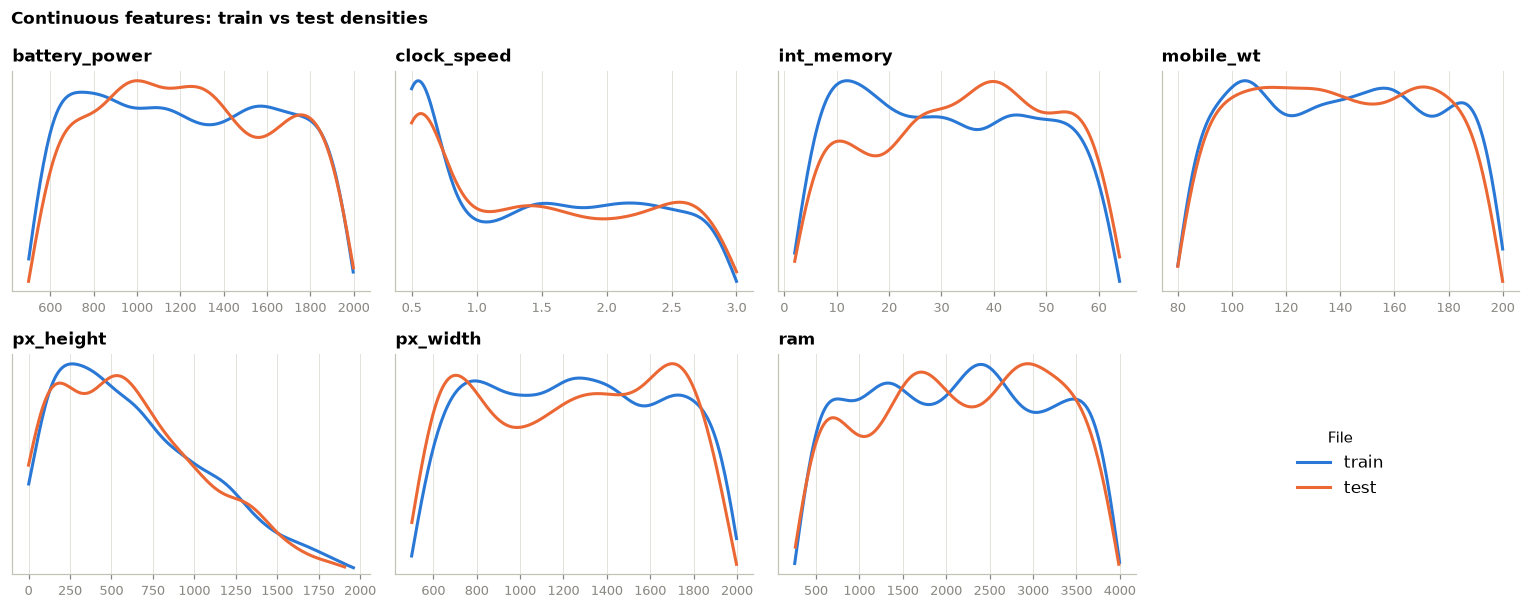

In [51]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.6))
for ax, col in zip(axes.ravel(), CONTINUOUS):
    for src in ["train", "test"]:
        sns.kdeplot(combined.loc[combined.source == src, col], ax=ax, color=SRC_COLORS[src],
                    linewidth=2, label=src, cut=0)
    ax.set_title(col, loc="left"); ax.set_xlabel(""); ax.set_ylabel(""); ax.set_yticks([])
axes.ravel()[-1].axis("off")
handles, labels = axes[0, 0].get_legend_handles_labels()
axes.ravel()[-1].legend(handles, labels, loc="center", fontsize=11, title="File")
fig.suptitle("Continuous features: train vs test densities", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

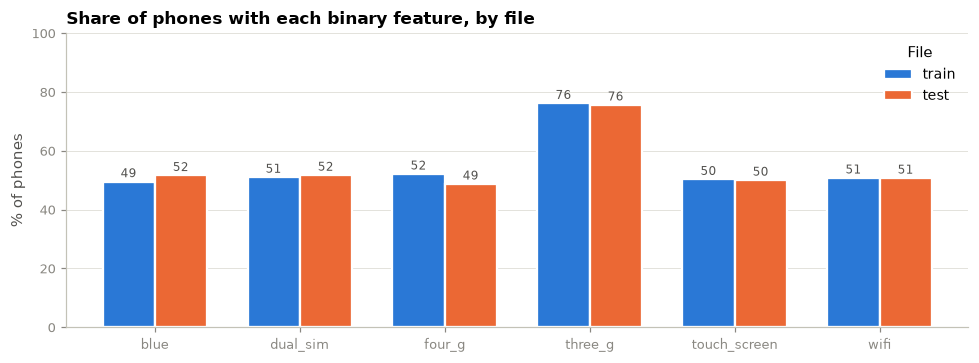

In [52]:
rate = combined.groupby("source")[BINARY].mean().T[["train", "test"]] * 100
ax = rate.plot(kind="bar", figsize=(9, 3.4), color=[SRC_COLORS["train"], SRC_COLORS["test"]], width=0.72, edgecolor="white", linewidth=1.5)
ax.set_title("Share of phones with each binary feature, by file", loc="left")
ax.set_ylabel("% of phones"); ax.set_xlabel(""); ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0); ax.grid(axis="x", visible=False); ax.legend(title="File")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.0f}", (p.get_x() + p.get_width() / 2, p.get_height() + 1.5), ha="center", fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

In [53]:
# Adversarial validation: can a model tell train rows from test rows?
# AUC near 0.5 means it cannot, so the two files look like the same population.
X_adv = combined[FEATURES]; y_adv = (combined["source"] == "test").astype(int)
auc = cross_val_score(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1),
                      X_adv, y_adv, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="roc_auc")
print(f"Adversarial validation ROC AUC: {auc.mean():.3f} (+/- {auc.std():.3f})")

Adversarial validation ROC AUC: 0.576 (+/- 0.034)


**Findings**

- Means and standard deviations are nearly identical across the two files. The largest gap is `sc_w`, at 0.10 of a standard deviation.
- Only 2 of 20 features differ at the 5% level (`int_memory` p = 0.024, `sc_w` p = 0.035). With 20 tests, one such result is expected by chance, and none remain after Bonferroni correction.
- A random forest trying to tell train rows from test rows scores ROC AUC 0.512, which is no better than guessing.
- **Conclusion:** train and test come from the same distribution. Combining them for feature-level EDA is reasonable, and performance measured on a validation split of train should carry over to test.

## 5. Target distribution (train only)

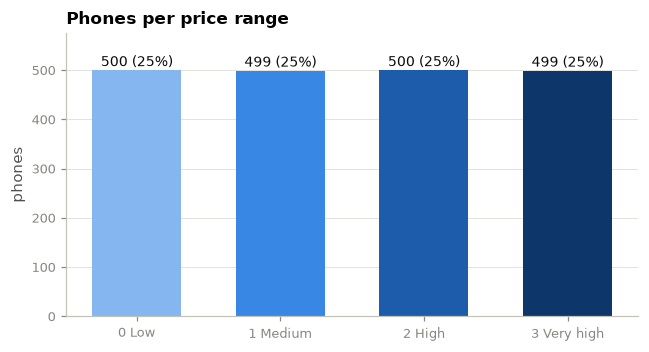

In [54]:
counts = train[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.3))
bars = ax.bar([PRICE_LABELS[i] for i in counts.index], counts.values, color=PRICE_COLORS, width=0.62)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 8, f"{v} ({v / len(train):.0%})", ha="center", fontsize=9, color=INK)
ax.set_title("Phones per price range", loc="left"); ax.set_ylabel("phones"); ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Findings**

- The target is perfectly balanced: 500 phones (25%) in each of the four price ranges.
- Accuracy is therefore a fair headline metric, no resampling or class weighting is needed, and a stratified train/validation split will keep the balance.
- The classes are ordered (0 < 1 < 2 < 3), so mistakes between neighbouring classes are less serious than mistakes two or three classes apart. The confusion matrix is worth reporting alongside accuracy.

## 6. Univariate analysis

Distributions use train + test together (3,000 phones) because Section 4 shows the two files follow the same distributions.

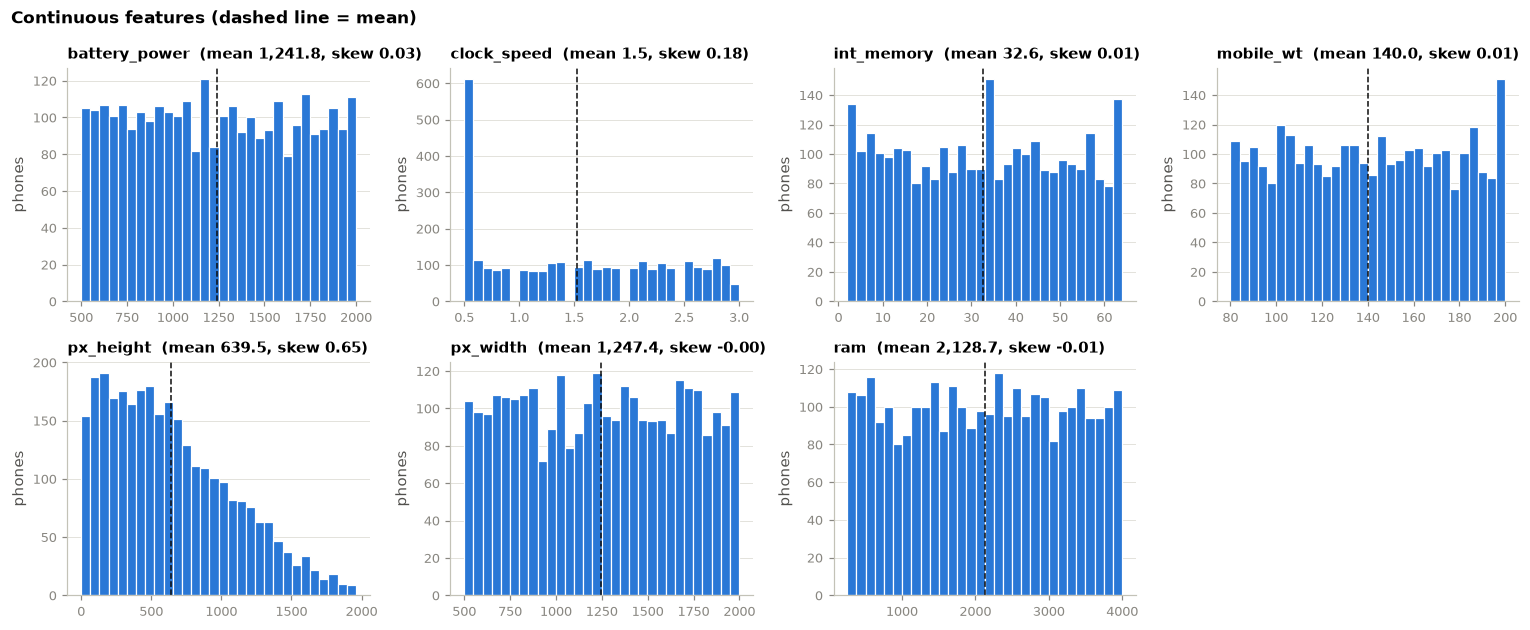

In [55]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.8))
for ax, col in zip(axes.ravel(), CONTINUOUS):
    ax.hist(combined[col], bins=30, color=BLUE, edgecolor="white", linewidth=0.8)
    ax.axvline(combined[col].mean(), color=INK, linewidth=1, linestyle="--")
    ax.set_title(f"{col}  (mean {combined[col].mean():,.1f}, skew {combined[col].skew():.2f})", loc="left", fontsize=9.5)
    ax.set_ylabel("phones"); ax.grid(axis="x", visible=False)
axes.ravel()[-1].axis("off")
fig.suptitle("Continuous features (dashed line = mean)", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

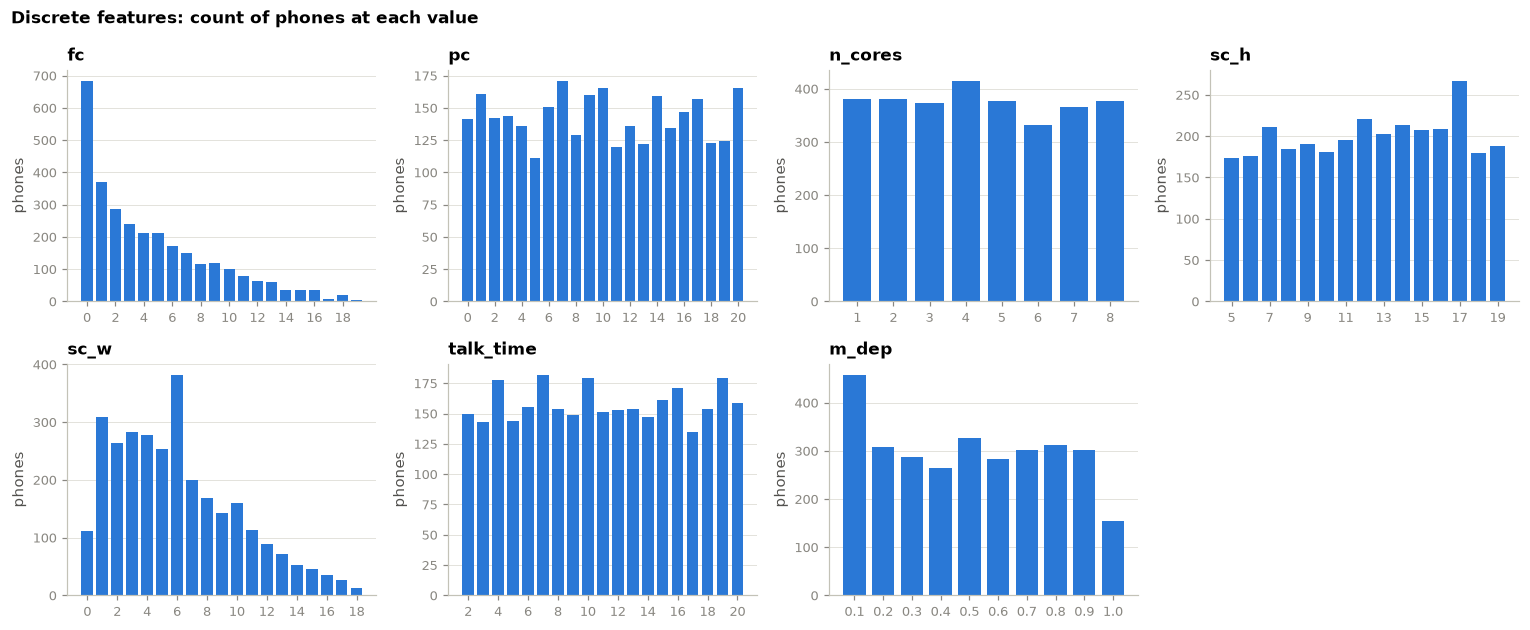

In [56]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.8))
for ax, col in zip(axes.ravel(), DISCRETE):
    vc = combined[col].value_counts().sort_index()
    step = vc.index.to_series().diff().min()
    ax.bar(vc.index, vc.values, color=BLUE, width=0.78 * step)
    ax.set_xticks(vc.index if len(vc) <= 10 else vc.index[::2])
    ax.set_title(col, loc="left"); ax.set_ylabel("phones"); ax.grid(axis="x", visible=False)
axes.ravel()[-1].axis("off")
fig.suptitle("Discrete features: count of phones at each value", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

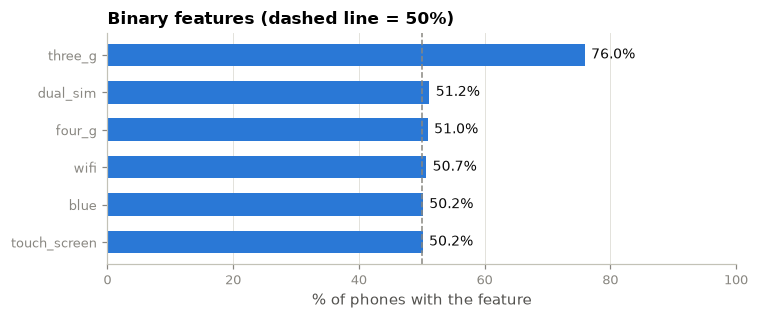

In [57]:
share = (combined[BINARY].mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(share.index, share.values, color=BLUE, height=0.6)
ax.axvline(50, color=MUTED, linewidth=1, linestyle="--")
for i, v in enumerate(share.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 100); ax.set_xlabel("% of phones with the feature"); ax.grid(axis="y", visible=False)
ax.set_title("Binary features (dashed line = 50%)", loc="left")
plt.tight_layout(); plt.show()

**Findings**

- `battery_power`, `int_memory`, `mobile_wt`, `px_width`, `ram`, `pc`, `n_cores`, `sc_h` and `talk_time` are spread roughly evenly across their ranges.
- `clock_speed` has a spike at its minimum: 612 of 3,000 phones (20.4%) are at 0.5 GHz.
- `fc` is right-skewed, with 0 MP the most common value (684 phones, 22.8%).
- `px_height` and `sc_w` are right-skewed. This follows from the constraints seen later: each is always less than or equal to its partner (`px_width`, `sc_h`).
- `m_dep` is most often 0.1 cm (459 phones) and least often 1.0 cm (155 phones).
- Five binary features are close to a 50/50 split. `three_g` is the exception at 76.0%.

## 7. Features vs price range (train only)

### 7.1 Strength of association with the target

Three views: linear/rank correlation, a significance test per feature (Kruskal-Wallis for numeric, chi-square for binary), and mutual information, which also picks up non-linear relationships.

In [58]:
X, y = train[FEATURES], train[TARGET]
assoc = pd.DataFrame({
    "pearson": X.corrwith(y),
    "spearman": X.corrwith(y, method="spearman"),
})
p, eff = {}, {}
for c in FEATURES:
    if c in BINARY:
        chi2, pv, _, _ = stats.chi2_contingency(pd.crosstab(train[c], y))
        p[c] = pv; eff[c] = np.sqrt(chi2 / len(train))                    # Cramer's V (min dim is 2)
    else:
        groups = [g[c].values for _, g in train.groupby(TARGET)]
        h, pv = stats.kruskal(*groups)
        p[c] = pv; eff[c] = (h - len(groups) + 1) / (len(train) - len(groups))   # epsilon squared
assoc["test"] = ["chi-square" if c in BINARY else "Kruskal-Wallis" for c in FEATURES]
assoc["p-value"] = pd.Series(p)
assoc["effect size"] = pd.Series(eff)
assoc["mutual info"] = mutual_info_classif(X, y, discrete_features=[c in BINARY for c in FEATURES], random_state=42)
assoc["significant at 5%"] = assoc["p-value"] < 0.05
assoc = assoc.sort_values("mutual info", ascending=False)
assoc.assign(**{"p-value": assoc["p-value"].map("{:.2e}".format)}).round(3)

,pearson,spearman,test,p-value,effect size,mutual info,significant at 5%
ram,0.917,0.917,Kruskal-Wallis,0.00e+00,0.841,0.847,True
battery_power,0.200,0.199,Kruskal-Wallis,2.99e-19,0.043,0.033,True
px_width,0.165,0.164,Kruskal-Wallis,6.65e-14,0.031,0.025,True
px_height,0.150,0.133,Kruskal-Wallis,1.91e-10,0.023,0.021,True
sc_h,0.023,0.023,Kruskal-Wallis,8.51e-02,0.002,0.015,False
n_cores,0.005,0.005,Kruskal-Wallis,4.23e-02,0.003,0.013,True
pc,0.033,0.033,Kruskal-Wallis,5.03e-01,-0.000,0.010,False
touch_screen,-0.031,-0.031,chi-square,2.80e-01,0.044,0.001,False
four_g,0.014,0.014,chi-square,3.82e-01,0.039,0.001,False
blue,0.021,0.021,chi-square,6.71e-01,0.028,0.000,False


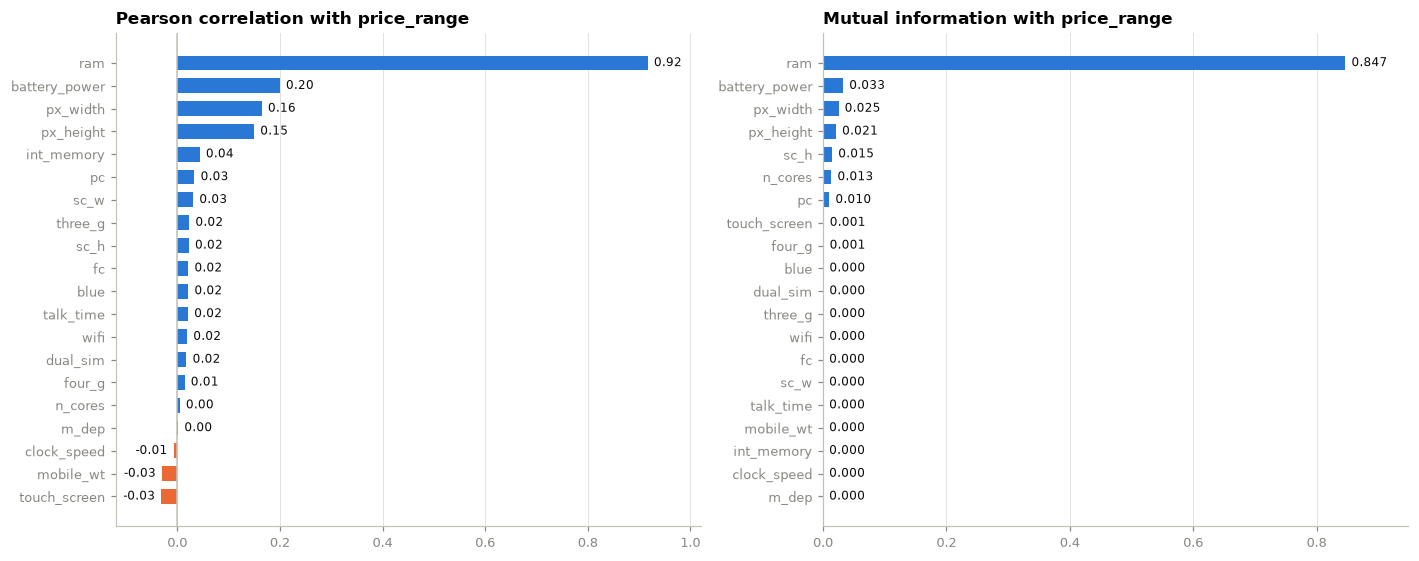

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
s = assoc["pearson"].sort_values()
axes[0].barh(s.index, s.values, color=["#eb6834" if v < 0 else BLUE for v in s.values], height=0.65)
axes[0].axvline(0, color="#c3c2b7", linewidth=1)
axes[0].set_title("Pearson correlation with price_range", loc="left"); axes[0].grid(axis="y", visible=False)
for i, v in enumerate(s.values):
    axes[0].text(v + (0.012 if v >= 0 else -0.012), i, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=INK)
axes[0].set_xlim(-0.12, 1.02)
m = assoc["mutual info"].sort_values()
axes[1].barh(m.index, m.values, color=BLUE, height=0.65)
axes[1].set_title("Mutual information with price_range", loc="left"); axes[1].grid(axis="y", visible=False)
for i, v in enumerate(m.values):
    axes[1].text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=8, color=INK)
axes[1].set_xlim(0, m.max() * 1.12)
plt.tight_layout(); plt.show()

### 7.2 Numeric features by price range

In [60]:
train.groupby(TARGET)[NUMERIC].mean().T.rename(columns=PRICE_LABELS).assign(
    **{"very high / low": lambda d: d["3 Very high"] / d["0 Low"]}
).round(2)

price_range,0 Low,1 Medium,2 High,3 Very high,very high / low
battery_power,"1,116.900","1,229.530","1,228.320","1,379.070",1.230
clock_speed,1.550,1.490,1.530,1.520,0.980
int_memory,31.170,32.180,30.920,33.960,1.090
mobile_wt,140.550,140.480,143.610,136.390,0.970
px_height,536.410,668.230,632.280,746.340,1.390
px_width,"1,150.270","1,252.420","1,234.050","1,368.600",1.190
ram,785.310,"1,678.930","2,582.820","3,448.750",4.390
fc,4.080,4.340,4.500,4.310,1.060
pc,9.570,9.920,10.020,10.150,1.060
n_cores,4.600,4.290,4.680,4.500,0.980


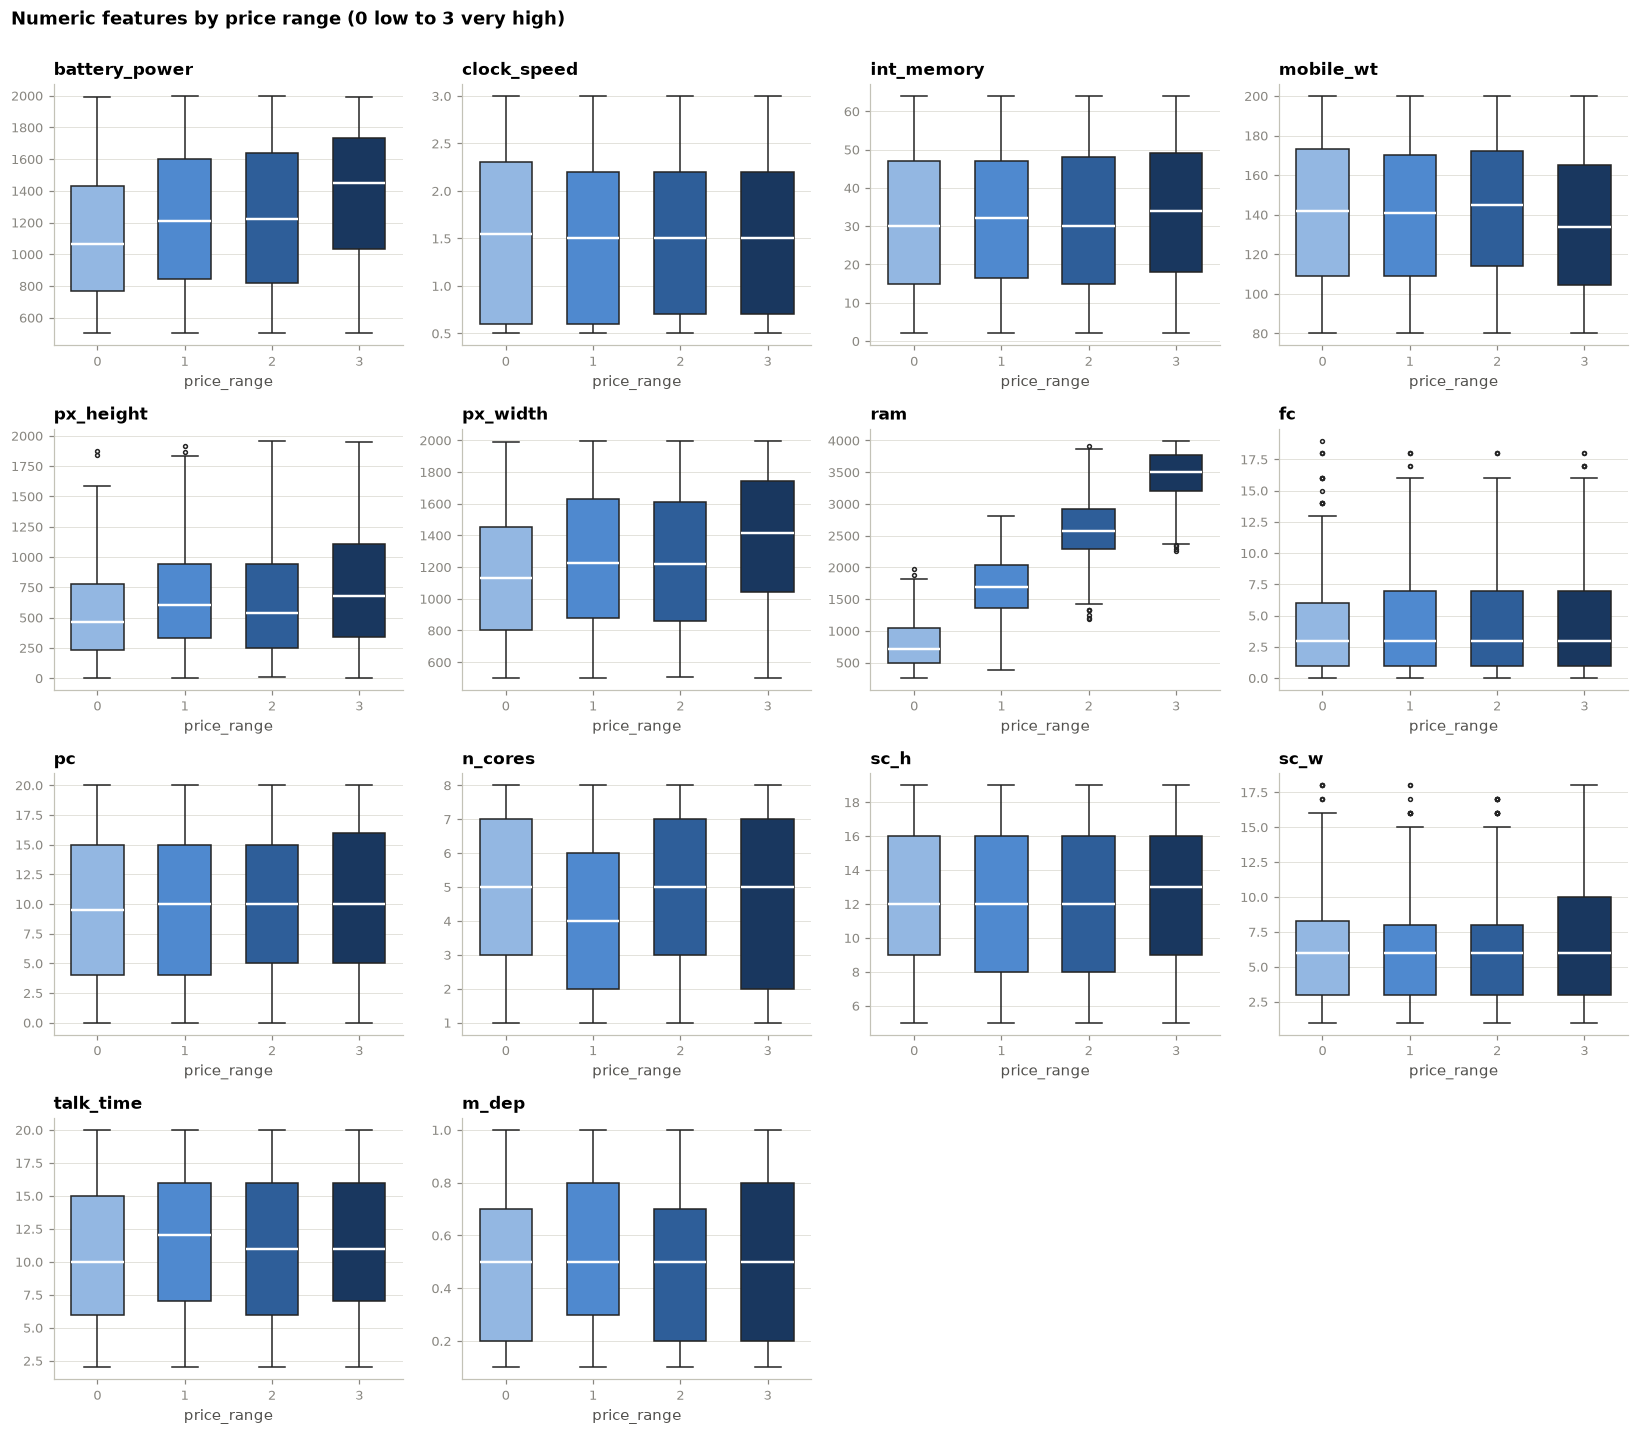

In [61]:
fig, axes = plt.subplots(4, 4, figsize=(15, 13))
for ax, col in zip(axes.ravel(), NUMERIC):
    sns.boxplot(data=train, x=TARGET, y=col, hue=TARGET, palette=PRICE_COLORS, legend=False, ax=ax,
                width=0.6, linewidth=1, fliersize=2.5,
                medianprops=dict(color="white", linewidth=1.6))
    ax.set_title(col, loc="left"); ax.set_xlabel("price_range"); ax.set_ylabel("")
    ax.grid(axis="x", visible=False)
for ax in axes.ravel()[len(NUMERIC):]:
    ax.axis("off")
fig.suptitle("Numeric features by price range (0 low to 3 very high)", x=0.01, y=1.0, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

### 7.3 RAM in detail

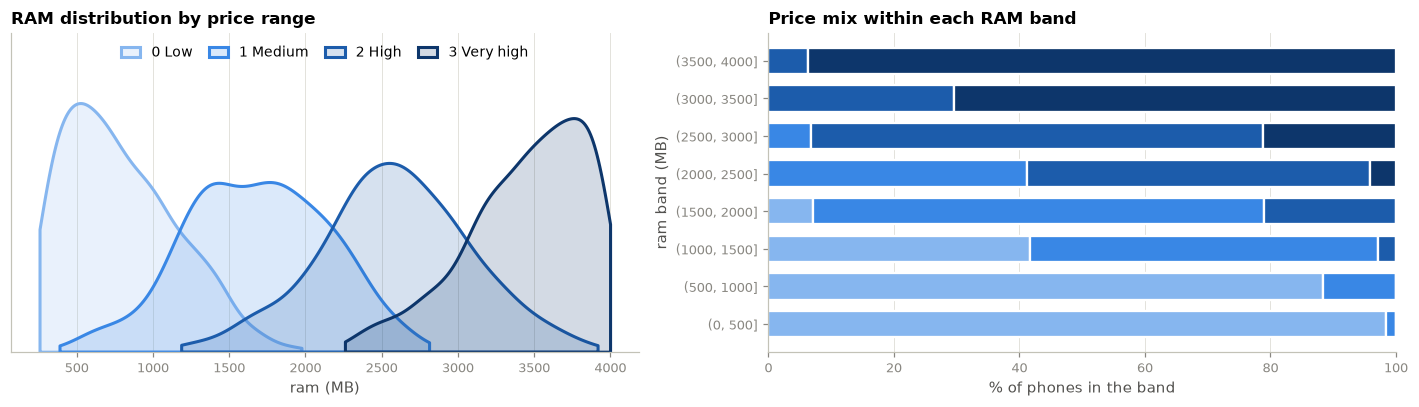

,min,25%,50%,75%,max
price_range,,,,,
0 Low,256.000,488.750,719.500,"1,037.000","1,974.000"
1 Medium,387.000,"1,354.000","1,686.000","2,034.500","2,811.000"
2 High,"1,185.000","2,292.750","2,577.000","2,927.000","3,916.000"
3 Very high,"2,259.000","3,207.000","3,508.000","3,765.500","3,998.000"


In [62]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for k in range(4):
    sns.kdeplot(train.loc[train[TARGET] == k, "ram"], ax=axes[0], color=PRICE_COLORS[k], linewidth=2,
                fill=True, alpha=0.18, label=PRICE_LABELS[k], cut=0)
axes[0].set_title("RAM distribution by price range", loc="left"); axes[0].set_xlabel("ram (MB)")
axes[0].set_yticks([]); axes[0].set_ylabel(""); axes[0].set_ylim(0, axes[0].get_ylim()[1] * 1.22)
axes[0].legend(ncol=4, loc="upper center", columnspacing=1.2, handlelength=1.4)

bands = pd.cut(train["ram"], bins=[0, 500, 1000, 1500, 2000, 2500, 3000, 3500, 4000])
mix = pd.crosstab(bands, train[TARGET], normalize="index") * 100
left = np.zeros(len(mix))
for k in range(4):
    axes[1].barh([str(i) for i in mix.index], mix[k].values, left=left, color=PRICE_COLORS[k],
                 edgecolor="white", linewidth=1.5, label=PRICE_LABELS[k], height=0.7)
    left += mix[k].values
axes[1].set_title("Price mix within each RAM band", loc="left"); axes[1].set_xlabel("% of phones in the band")
axes[1].set_ylabel("ram band (MB)"); axes[1].set_xlim(0, 100); axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

train.groupby(TARGET)["ram"].describe()[["min", "25%", "50%", "75%", "max"]].rename(index=PRICE_LABELS)

In [63]:
# How far does RAM alone get? Cross-validated accuracy of a shallow tree using only ram
from sklearn.tree import DecisionTreeClassifier
cv = StratifiedKFold(5, shuffle=True, random_state=42)
acc_ram = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=42), train[["ram"]], y, cv=cv).mean()
top4 = ["ram", "battery_power", "px_height", "px_width"]
acc_top4 = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), train[top4], y, cv=cv).mean()
acc_all = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), X, y, cv=cv).mean()
print(f"Baseline (always guess one class)        : {1 / 4:.3f}")
print(f"Shallow tree, ram only                   : {acc_ram:.3f}")
print(f"Random forest, ram + battery + px h/w    : {acc_top4:.3f}")
print(f"Random forest, all 20 features           : {acc_all:.3f}")

Baseline (always guess one class)        : 0.250
Shallow tree, ram only                   : 0.749
Random forest, ram + battery + px h/w    : 0.913
Random forest, all 20 features           : 0.890


### 7.4 Binary features by price range

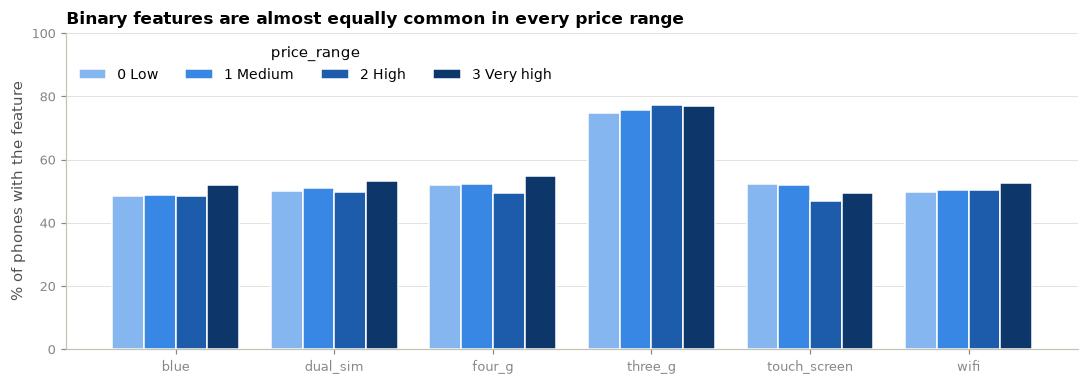

price_range,0 Low,1 Medium,2 High,3 Very high
blue,48.600,48.900,48.600,51.900
dual_sim,50.000,51.100,49.800,53.100
four_g,51.800,52.300,49.400,54.900
three_g,74.600,75.600,77.400,77.000
touch_screen,52.400,52.100,47.000,49.500
wifi,49.600,50.500,50.400,52.500


In [64]:
rate = train.groupby(TARGET)[BINARY].mean().T * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
w = 0.2
for k in range(4):
    ax.bar(np.arange(len(BINARY)) + (k - 1.5) * w, rate[k].values, width=w, color=PRICE_COLORS[k],
           edgecolor="white", linewidth=1, label=PRICE_LABELS[k])
ax.set_xticks(np.arange(len(BINARY))); ax.set_xticklabels(BINARY)
ax.set_ylabel("% of phones with the feature"); ax.set_ylim(0, 100); ax.grid(axis="x", visible=False)
ax.set_title("Binary features are almost equally common in every price range", loc="left")
ax.legend(title="price_range", ncol=4, loc="upper left")
plt.tight_layout(); plt.show()
rate.rename(columns=PRICE_LABELS).round(1)

**Findings**

- **`ram` dominates.** Its correlation with `price_range` is 0.917 and its mutual information is 0.844, against 0.035 for the next feature. Mean RAM rises from 785 MB (low) to 1,679, 2,583 and 3,449 MB (very high), a factor of 4.4.
- **Three features add a modest signal:** `battery_power` (r = 0.20), `px_width` (0.17) and `px_height` (0.15).
- **The other 16 features show almost no relationship**, with correlations between -0.03 and 0.04. `mobile_wt` (p = 0.013), `int_memory` (p = 0.033) and `n_cores` (p = 0.049) pass the 5% test, but their effect sizes are at most 0.004 and none would survive correction for 20 tests.
- **No binary feature is significant** (smallest p = 0.275). Bluetooth, WiFi, 3G, 4G, dual SIM and touch screen are about equally common in every price range.
- **RAM alone does not fully separate the classes.** Neighbouring classes overlap: in the 2,000 to 2,500 MB band, 41.2% of phones are medium and 54.6% are high. Classes two steps apart almost never overlap.
- **Quick accuracy checks (5-fold cross-validation, untuned):** a shallow tree on `ram` alone reaches 75.0%; a random forest on `ram`, `battery_power`, `px_height` and `px_width` reaches 91.4%; a random forest on all 20 features reaches 88.8%. Adding the 16 weak features made the forest slightly worse, so feature selection is worth testing.

## 8. Relationships between features

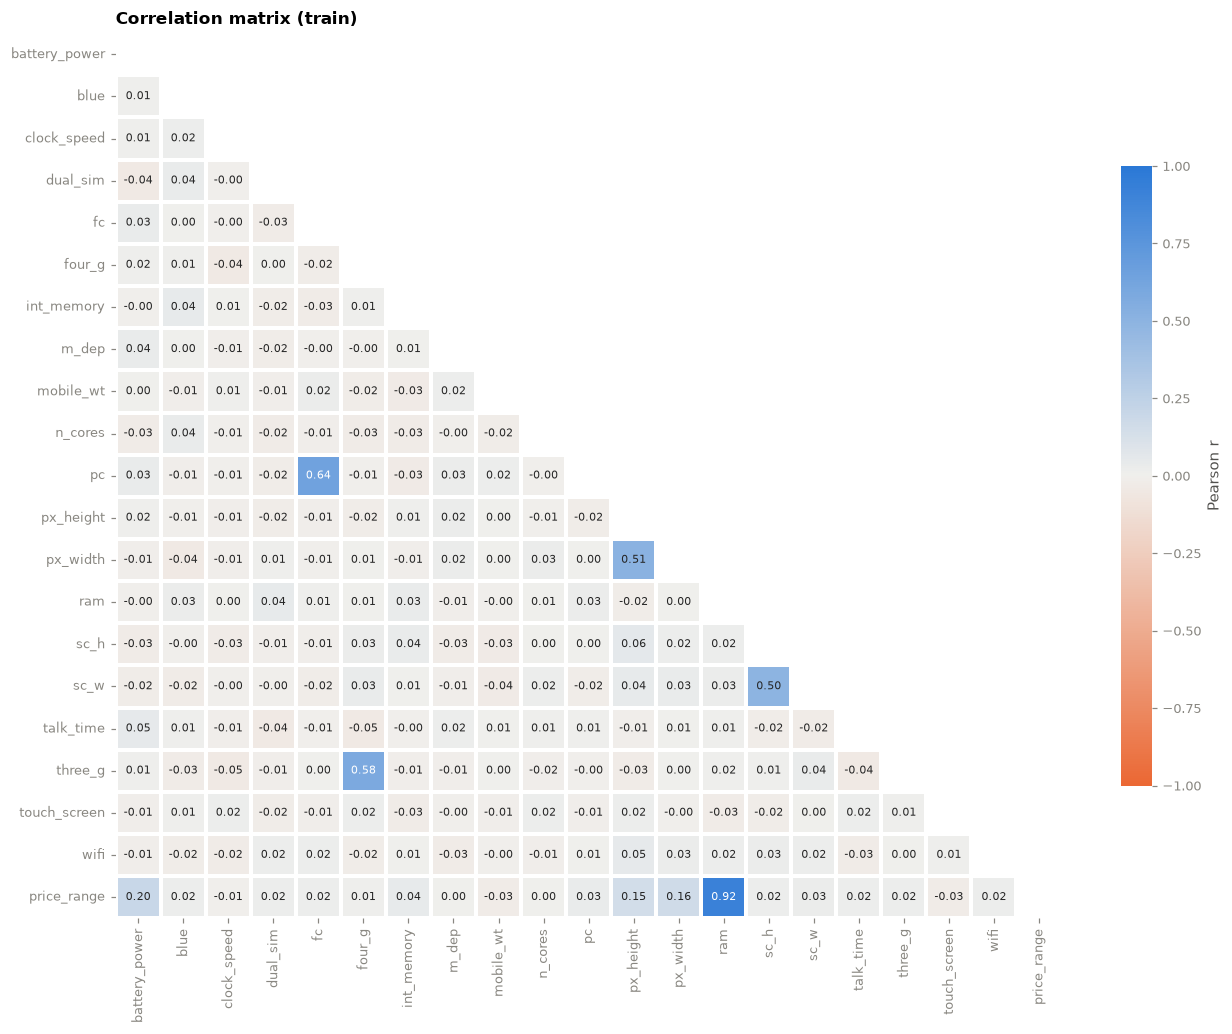

Strongest feature-feature correlations:
fc             pc           0.645
four_g         three_g      0.584
px_height      px_width     0.512
sc_h           sc_w         0.498
px_height      sc_h         0.059
battery_power  talk_time    0.052
px_height      wifi         0.050
clock_speed    three_g     -0.047

Feature pairs with |r| > 0.1: 4 of 190


In [65]:
corr = train[FEATURES + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=1.5, linecolor="white", cbar_kws={"shrink": 0.7, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation matrix (train)", loc="left"); ax.grid(False)
plt.tight_layout(); plt.show()

pairs = corr.loc[FEATURES, FEATURES].where(np.triu(np.ones((len(FEATURES),) * 2), 1).astype(bool)).stack().dropna()
pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)
print("Strongest feature-feature correlations:")
print(pairs.head(8).round(3).to_string())
print("\nFeature pairs with |r| > 0.1:", int((pairs.abs() > 0.1).sum()), "of", len(pairs))

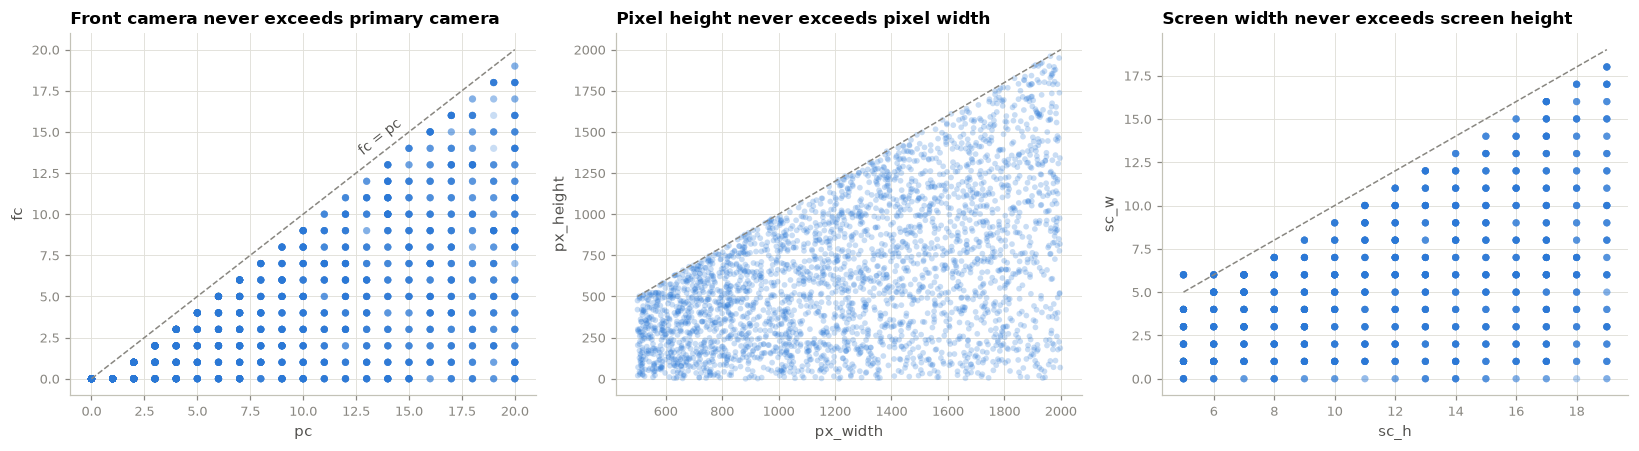

3G vs 4G (train + test):
four_g      0     1   All
three_g                  
0         721     0   721
1         749  1528  2277
All      1470  1528  2998


In [66]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.scatterplot(data=combined, x="pc", y="fc", ax=axes[0], color=BLUE, alpha=0.25, s=22, edgecolor="none")
lim = [0, 20]; axes[0].plot(lim, lim, color=MUTED, linewidth=1, linestyle="--")
axes[0].text(12.5, 13.6, "fc = pc", color="#52514e", fontsize=9, rotation=38)
axes[0].set_title("Front camera never exceeds primary camera", loc="left")

sns.scatterplot(data=combined, x="px_width", y="px_height", ax=axes[1], color=BLUE, alpha=0.25, s=14, edgecolor="none")
axes[1].plot([500, 2000], [500, 2000], color=MUTED, linewidth=1, linestyle="--")
axes[1].set_title("Pixel height never exceeds pixel width", loc="left")

sns.scatterplot(data=combined, x="sc_h", y="sc_w", ax=axes[2], color=BLUE, alpha=0.2, s=22, edgecolor="none")
axes[2].plot([5, 19], [5, 19], color=MUTED, linewidth=1, linestyle="--")
axes[2].set_title("Screen width never exceeds screen height", loc="left")
plt.tight_layout(); plt.show()

print("3G vs 4G (train + test):")
print(pd.crosstab(combined.three_g, combined.four_g, margins=True).to_string())

**Findings**

- Only 4 of 190 feature pairs have a correlation above 0.1 in absolute value: `fc` and `pc` (0.645), `four_g` and `three_g` (0.584), `px_height` and `px_width` (0.511), `sc_h` and `sc_w` (0.506).
- Each of these comes from a hard constraint in the data, visible as the empty triangle in the scatter plots: the first value of each pair never exceeds the second.
- 4G implies 3G: 721 phones have neither, 749 have 3G only, 1,530 have both, and none have 4G only. The two columns could be merged into one three-level "network generation" feature.
- All other features are practically independent of each other, so multicollinearity is not a concern. The strongest correlation is 0.645.
- `ram` is uncorrelated with every other feature (largest value 0.04), so its signal is not duplicated anywhere else.

## 9. Multivariate view (train only)

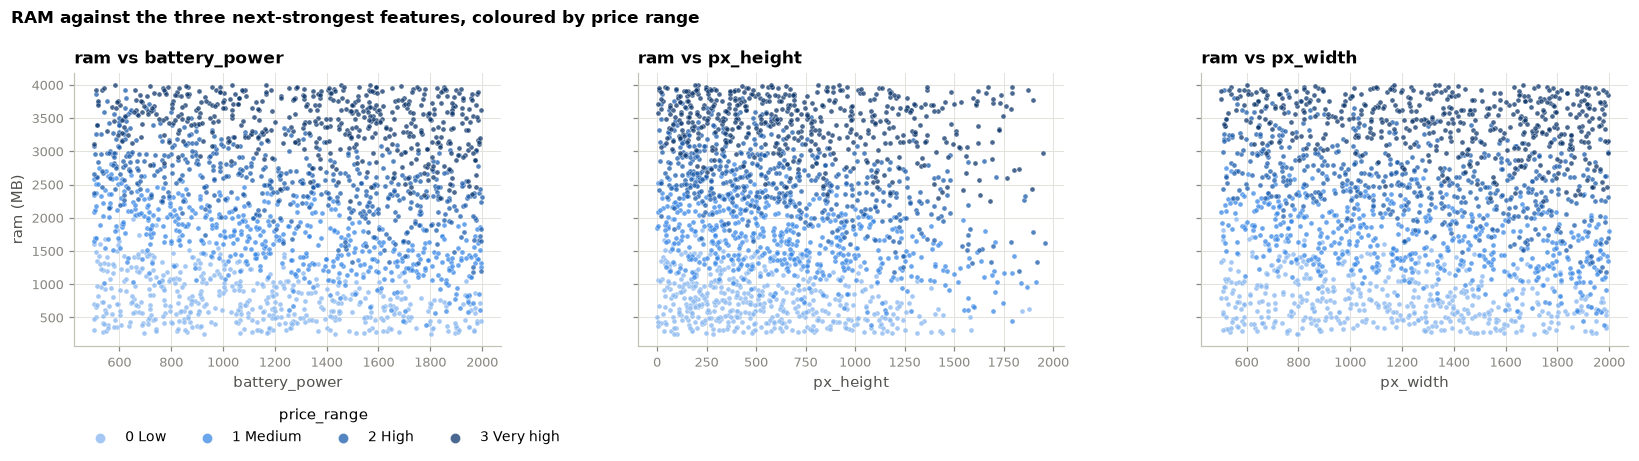

In [67]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, col in zip(axes, ["battery_power", "px_height", "px_width"]):
    for k in range(4):
        d = train[train[TARGET] == k]
        ax.scatter(d[col], d["ram"], s=11, color=PRICE_COLORS[k], alpha=0.75, edgecolor="white", linewidth=0.3,
                   label=PRICE_LABELS[k])
    ax.set_xlabel(col); ax.set_title(f"ram vs {col}", loc="left")
axes[0].set_ylabel("ram (MB)")
axes[0].legend(title="price_range", markerscale=2, loc="upper left", bbox_to_anchor=(0, -0.18), ncol=4)
fig.suptitle("RAM against the three next-strongest features, coloured by price range",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

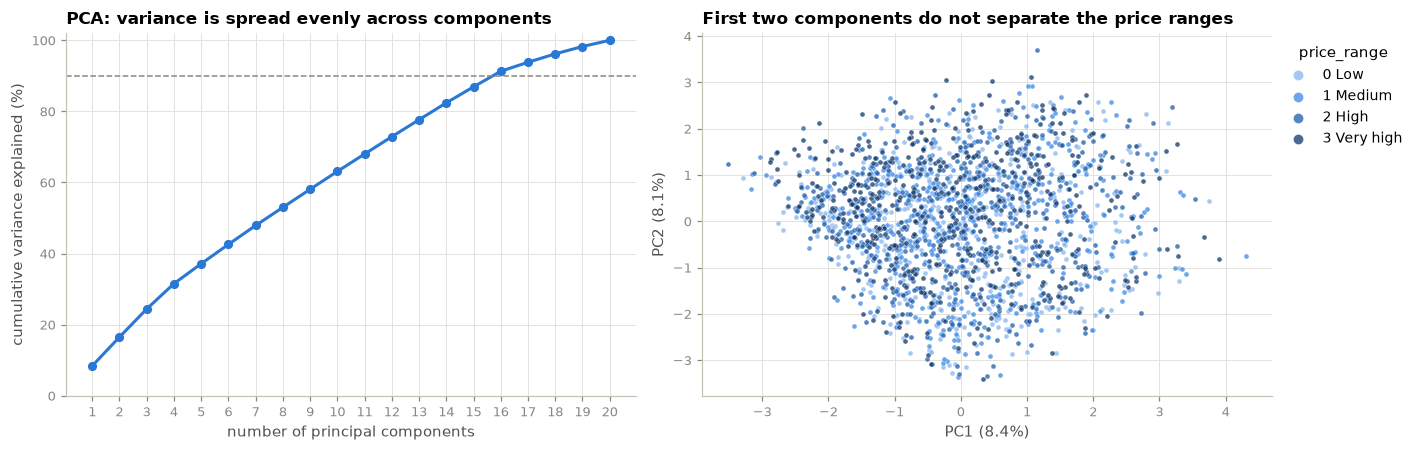

Components needed for 90% of variance: 16 of 20


In [68]:
Z = StandardScaler().fit_transform(train[FEATURES])
pca = PCA().fit(Z)
pcs = pca.transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
cum = np.cumsum(pca.explained_variance_ratio_) * 100
axes[0].plot(range(1, len(cum) + 1), cum, color=BLUE, linewidth=2, marker="o", markersize=5)
axes[0].axhline(90, color=MUTED, linestyle="--", linewidth=1)
axes[0].set_xticks(range(1, len(cum) + 1)); axes[0].set_ylim(0, 102)
axes[0].set_xlabel("number of principal components"); axes[0].set_ylabel("cumulative variance explained (%)")
axes[0].set_title("PCA: variance is spread evenly across components", loc="left")
for k in range(4):
    m_ = (y == k).values
    axes[1].scatter(pcs[m_, 0], pcs[m_, 1], s=11, color=PRICE_COLORS[k], alpha=0.75, edgecolor="white", linewidth=0.3, label=PRICE_LABELS[k])
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"); axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[1].set_title("First two components do not separate the price ranges", loc="left")
axes[1].legend(title="price_range", markerscale=2, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout(); plt.show()
print("Components needed for 90% of variance:", int(np.argmax(cum >= 90) + 1), "of", len(cum))

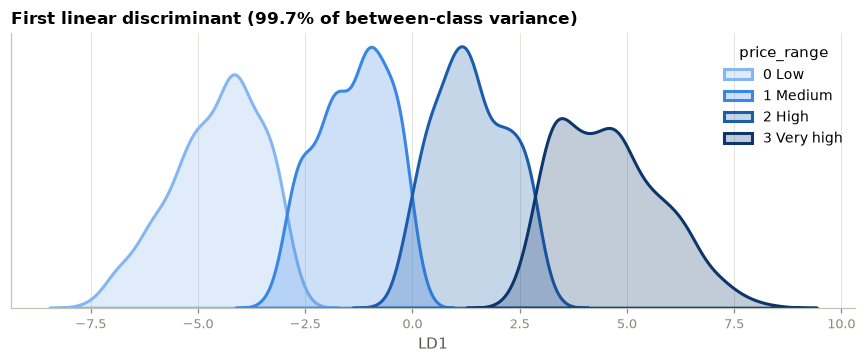

Largest LD1 weights (standardised features):
ram              3.374
battery_power    0.743
px_height        0.407
px_width         0.404
mobile_wt       -0.108
int_memory       0.056

5-fold CV accuracy of LDA on all standardised features: 0.947


In [69]:
# A linear combination of the top features separates classes far better than PCA does
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda = LinearDiscriminantAnalysis().fit(Z, y)
ld = lda.transform(Z)
fig, ax = plt.subplots(figsize=(8, 3.4))
for k in range(4):
    sns.kdeplot(ld[(y == k).values, 0], ax=ax, color=PRICE_COLORS[k], fill=True, alpha=0.25, linewidth=2, label=PRICE_LABELS[k])
ax.set_title(f"First linear discriminant ({lda.explained_variance_ratio_[0]:.1%} of between-class variance)", loc="left")
ax.set_xlabel("LD1"); ax.set_yticks([]); ax.set_ylabel(""); ax.legend(title="price_range")
plt.tight_layout(); plt.show()
load = pd.Series(lda.scalings_[:, 0], index=FEATURES)
print("Largest LD1 weights (standardised features):")
print(load.reindex(load.abs().sort_values(ascending=False).index).head(6).round(3).to_string())
print(f"\n5-fold CV accuracy of LDA on all standardised features: "
      f"{cross_val_score(LinearDiscriminantAnalysis(), Z, y, cv=cv).mean():.3f}")

**Findings**

- **PCA is not useful here.** Because the features are nearly independent, each component explains only about 5 to 8% of the variance (PC1 8.4%, PC2 8.1%), and 16 of 20 components are needed to reach 90%. The first two components do not separate the price ranges.
- **A supervised linear projection separates the classes well.** The first linear discriminant is driven by `ram` (weight 3.37), then `battery_power` (0.74), `px_height` (0.41) and `px_width` (0.40). All four weights are positive, so more battery or more pixels lowers the RAM needed to reach the next price range.
- LDA on all standardised features scores 94.3% in 5-fold cross-validation, higher than the untuned random forest (88.8%). The class boundaries look close to linear, so **logistic regression and linear SVM should be included as candidates**, not only tree ensembles.

## 10. Candidate engineered features (train only)

A quick test of whether combining related columns gives a stronger signal than the originals. These are suggestions to evaluate during modelling, not final features.

In [70]:
fe = pd.DataFrame({
    "px_area = px_height * px_width": train.px_height * train.px_width,
    "sc_area = sc_h * sc_w": train.sc_h * train.sc_w,
    "sc_diag = sqrt(sc_h^2 + sc_w^2)": np.sqrt(train.sc_h ** 2 + train.sc_w ** 2),
    "total_camera = fc + pc": train.fc + train.pc,
    "battery_per_gram = battery_power / mobile_wt": train.battery_power / train.mobile_wt,
    "n_connectivity = blue + wifi + 3g + 4g + dual_sim": train[["blue", "wifi", "three_g", "four_g", "dual_sim"]].sum(axis=1),
    "cpu_power = clock_speed * n_cores": train.clock_speed * train.n_cores,
})
ref = train[["px_height", "px_width", "battery_power", "ram"]].rename(columns=lambda c: c + " (original)")
both = pd.concat([fe, ref], axis=1)
res = pd.DataFrame({
    "spearman with price_range": both.corrwith(y, method="spearman"),
    "mutual info": mutual_info_classif(both, y, random_state=42),
}).sort_values("mutual info", ascending=False)
res.round(3)

,spearman with price_range,mutual info
ram (original),0.917,0.847
battery_per_gram = battery_power / mobile_wt,0.184,0.037
battery_power (original),0.199,0.034
sc_diag = sqrt(sc_h^2 + sc_w^2),0.031,0.032
px_width (original),0.164,0.026
px_height (original),0.133,0.026
sc_area = sc_h * sc_w,0.012,0.023
px_area = px_height * px_width,0.159,0.018
cpu_power = clock_speed * n_cores,0.003,0.000
total_camera = fc + pc,0.031,0.000


**Findings**

- None of the candidate features clearly beats the originals. `battery_per_gram` has mutual information 0.036 against 0.033 for `battery_power` (a difference within noise) and a lower rank correlation (0.185 against 0.200).
- `px_area` (rank correlation 0.158) is no stronger than `px_width` alone (0.165).
- Screen size, camera total, CPU power and connectivity count carry almost no signal, like the columns they are built from.
- Feature engineering is unlikely to add much on this dataset. Any engineered feature should be kept only if it improves cross-validated accuracy.

## 11. Summary and recommendations for preprocessing

### Key findings

1. **Clean structure.** 2,000 labelled train phones and 1,000 unlabelled test phones, 20 numeric features, no missing values, no duplicates, no categorical columns.
2. **Hidden invalid values.** `sc_w` = 0 in 292 phones (180 train, 112 test) and `px_height` below 100 px in 249 phones (150 train, 99 test).
3. **Train and test match.** Adversarial validation AUC is 0.512 and no feature differs after multiple-testing correction.
4. **Balanced target.** 500 phones per price range.
5. **One dominant predictor.** `ram` (r = 0.917) carries most of the signal; `battery_power`, `px_width` and `px_height` add a little; the other 16 features add almost nothing.
6. **Features are nearly independent.** Only four pairs correlate, all because of built-in constraints.
7. **Class boundaries are close to linear.** LDA reaches 94.3% cross-validated accuracy without tuning.

### Recommendations for preprocessing

| Topic | Recommendation | Reason |
|---|---|---|
| Missing values, duplicates | Nothing to do | None found in either file |
| Encoding | Nothing to do | All columns are numeric; binary columns are already 0/1 |
| `sc_w` = 0 | Treat as missing and impute (for example the median `sc_w` of phones with the same `sc_h`), or leave as is. Do **not** drop the rows | 9 to 11% of rows are affected, and test rows cannot be dropped. `sc_w` has almost no relationship with price (r = 0.04), so the choice will barely change accuracy |
| `px_height` near 0 | Impute the 4 zero values; the under-100 px values are a judgement call | `px_height` is one of the four useful features, so check any change with cross-validation |
| `pc` = 0, `fc` = 0 | Keep | Plausibly means no camera |
| Outliers | Do not remove | The few flagged values are valid high values |
| Skew transforms | Not needed | Highest skew is 1.02 (`fc`), a feature with no signal |
| Scaling | Standardise for logistic regression, SVM and KNN. Fit the scaler on the training split only | Feature scales differ by a factor of thousands |
| Class imbalance | Nothing to do; use a stratified split | Target is perfectly balanced |
| Feature selection | Compare all 20 features against a reduced set led by `ram`, `battery_power`, `px_height`, `px_width` | The weak features lowered random forest accuracy from 91.4% to 88.8% |
| Same treatment for both files | Apply identical cleaning rules to train and test, with any imputation values learned from train | Prevents leakage and keeps the GUI inputs consistent with training |
